# 03 — 3D settling (MuJoCo)

A piece rests on the board; an identical piece is released above it, off center. MuJoCo simulates both as free
rigid bodies made of convex parts (DD-STACK SP-8). Four release scenarios, three friction values. MuJoCo
installs from a wheel on Windows (no compiler). An earlier run used PyBullet; docs/method.md compares them.

In [1]:
# Setup: works from this folder whether or not the package was pip-installed
import sys, os, json
HERE = os.path.abspath("")
ROOT = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
import stackpieces
print("stackpieces", stackpieces.__version__, "| folder", os.path.relpath(ROOT))
CONSTRAINTS = os.path.join(ROOT, "constraints", "checkers_rot3u.json")
REFERENCE = os.path.join(ROOT, "results", "reference", "results.json")
c = json.load(open(CONSTRAINTS))
QUICK = True   # True: a few minutes, coarse. False: the full reference run (tens of minutes).

stackpieces 0.1.0 | folder ..


In [2]:
from stackpieces.geometry import make_piece, PRESETS
from stackpieces.sim3d import Stack3D, SCENARIOS, outcome_map
g = make_piece(PRESETS["S40"])
st = Stack3D(g)
for e in (0, 3, 6, 7, 9):
    r = st.simulate(e, d=1.0, mu=0.4)
    print(f"offset {e} mm: {r['code']:8s} final offset {r['dxy']:.2f} mm, tilt {r['tilt']:.1f} deg, height {r['dz']:.2f} mm")

offset 0 mm: seated   final offset 0.25 mm, tilt 0.0 deg, height 12.00 mm


offset 3 mm: seated   final offset 0.44 mm, tilt 0.0 deg, height 12.00 mm


offset 6 mm: seated   final offset 0.29 mm, tilt 0.0 deg, height 12.00 mm


offset 7 mm: perched  final offset 2.13 mm, tilt 18.1 deg, height 14.80 mm


offset 9 mm: fell     final offset 59.58 mm, tilt 134.7 deg, height 16.97 mm


In [3]:
offs = list(range(0, 13, 2)) if QUICK else list(range(13))
mus = (0.4,) if QUICK else (0.25, 0.4, 0.55)
scen = ["place", "slide"] if QUICK else list(SCENARIOS)
om = outcome_map(g, offs, mus=mus, scenarios=scen, progress=lambda s, mu, row: print(f"{s:7s} mu {mu}: {row}"))

place   mu 0.4: ####...


slide   mu 0.4: ###....


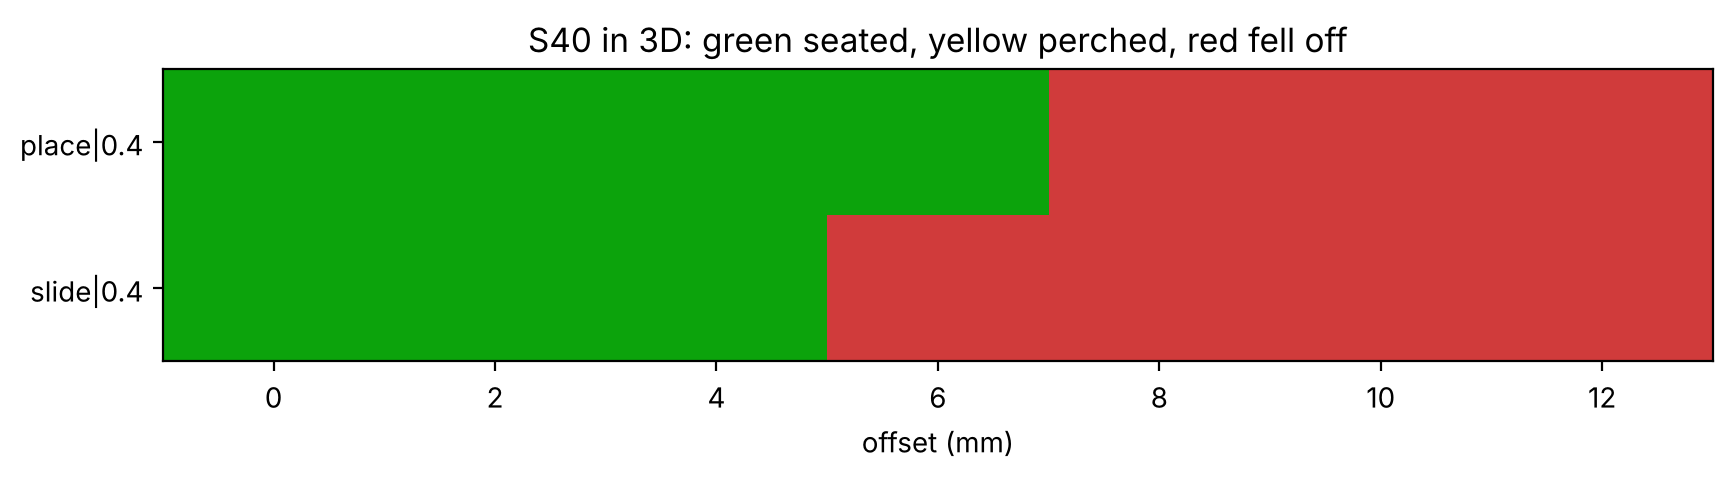

In [4]:
from matplotlib.colors import ListedColormap
code = {"seated": 0, "perched": 1, "fell": 2, "knocked": 3}
keys = list(om["results"])
A = np.array([[code[r["code"]] for r in om["results"][k]] for k in keys])
fig, ax = plt.subplots(figsize=(10, 0.45 * len(keys) + 1))
ax.imshow(A, cmap=ListedColormap(["#0ca30c", "#fab219", "#d03b3b", "#ec835a"]), vmin=0, vmax=3, aspect="auto")
ax.set_yticks(range(len(keys)), keys); ax.set_xticks(range(len(offs)), offs); ax.set_xlabel("offset (mm)")
ax.set_title("S40 in 3D: green seated, yellow perched, red fell off")
plt.show()

## Compare with the reference run

Counts how many cells differ from `results/reference` for the same scenario and friction. One cell is within the
normal spread of a model this sensitive at the edge of capture.

In [5]:
import os
if os.path.exists(REFERENCE):
    ref = json.load(open(REFERENCE))["map3d"]["S40"]
    for k, row in om["results"].items():
        if k in ref["results"]:
            rr = ref["results"][k]
            diff = sum(row[i]["code"] != rr[ref["offsets"].index(e)]["code"] for i, e in enumerate(offs) if e in ref["offsets"])
            print(f"{k:12s} cells differing from the reference: {diff}")

place|0.4    cells differing from the reference: 0
slide|0.4    cells differing from the reference: 0
